In [1]:
import pandas as pd

transaction = pd.read_csv("../data/dataset-ieee/train_transaction.csv")
identity = pd.read_csv("../data/dataset-ieee/train_identity.csv")

print(transaction.shape)
print(identity.shape)

transaction.head()

(590540, 394)
(144233, 41)


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [2]:
import pandas as pd

files_summary = pd.DataFrame({
    "File": [
        "train_transaction.csv",
        "train_identity.csv"
    ],
    "Rows": [
        transaction.shape[0],
        identity.shape[0]
    ],
    "Columns": [
        transaction.shape[1],
        identity.shape[1]
    ]
})

files_summary

# files_summary.style.set_caption("Table 3.1. Number of observations and attributes for each file")

,File,Rows,Columns
0,train_transaction.csv,590540,394
1,train_identity.csv,144233,41


In [3]:
# fraud distribution
transaction["isFraud"].value_counts()

isFraud
0    569877
1     20663
Name: count, dtype: int64

In [8]:
identity.shape

(144233, 41)

In [9]:
transaction.shape


(590540, 394)

In [4]:
# fraud percent
transaction["isFraud"].mean()

np.float64(0.03499000914417313)

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

class_counts = transaction["isFraud"].value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Class": ["Legitimate", "Fraudulent"],
    "Count": class_counts.values,
    "Percentage": (class_counts.values / len(transaction) * 100).round(2)
})

class_distribution

,Class,Count,Percentage
0,Legitimate,569877,96.5
1,Fraudulent,20663,3.5


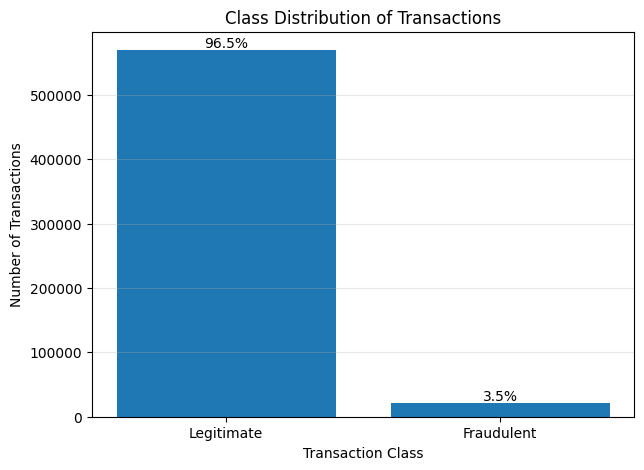

In [11]:
plt.figure(figsize=(7, 5))

bars = plt.bar(
    class_distribution["Class"],
    class_distribution["Count"]
)

plt.title("Class Distribution of Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

for bar, percentage in zip(bars, class_distribution["Percentage"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage}%",
        ha="center",
        va="bottom"
    )

plt.grid(axis="y", alpha=0.3)
plt.show()

In [12]:
transaction["isFraud"].value_counts(normalize=True) * 100

isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64

In [13]:
# missing values
transaction.isnull().mean().sort_values(ascending=False).head(20)

dist2    0.936284
D7       0.934099
D13      0.895093
D14      0.894695
D12      0.890410
D6       0.876068
D9       0.873123
D8       0.873123
V153     0.861237
V149     0.861237
V141     0.861237
V146     0.861237
V154     0.861237
V162     0.861237
V142     0.861237
V158     0.861237
V161     0.861237
V157     0.861237
V138     0.861237
V139     0.861237
dtype: float64

In [14]:
# types of variables
transaction.dtypes.value_counts()

float64    376
str         14
int64        4
Name: count, dtype: int64

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

product_stats = (
    transaction
    .groupby("ProductCD")
    .agg(
        total_transactions=("TransactionID", "count"),
        fraud_transactions=("isFraud", "sum")
    )
    .reset_index()
)

product_stats["fraud_rate_percent"] = (
    product_stats["fraud_transactions"] 
    / product_stats["total_transactions"] 
    * 100
).round(2)

product_stats = product_stats.sort_values(
    by="total_transactions",
    ascending=False
)

product_stats

,ProductCD,total_transactions,fraud_transactions,fraud_rate_percent
4,W,439670,8969,2.04
0,C,68519,8008,11.69
2,R,37699,1426,3.78
1,H,33024,1574,4.77
3,S,11628,686,5.90


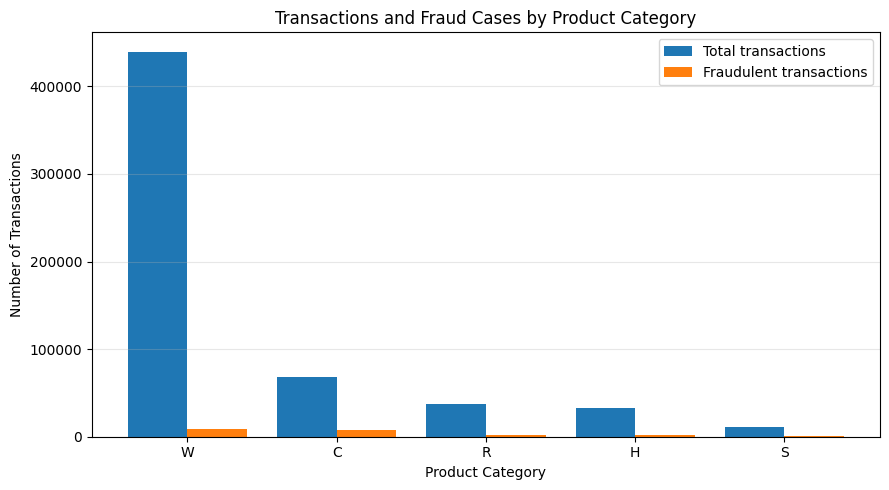

In [17]:
plt.figure(figsize=(9, 5))

x = range(len(product_stats))
bar_width = 0.4

plt.bar(
    [i - bar_width / 2 for i in x],
    product_stats["total_transactions"],
    width=bar_width,
    label="Total transactions"
)

plt.bar(
    [i + bar_width / 2 for i in x],
    product_stats["fraud_transactions"],
    width=bar_width,
    label="Fraudulent transactions"
)

plt.xticks(x, product_stats["ProductCD"])
plt.title("Transactions and Fraud Cases by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Transactions")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

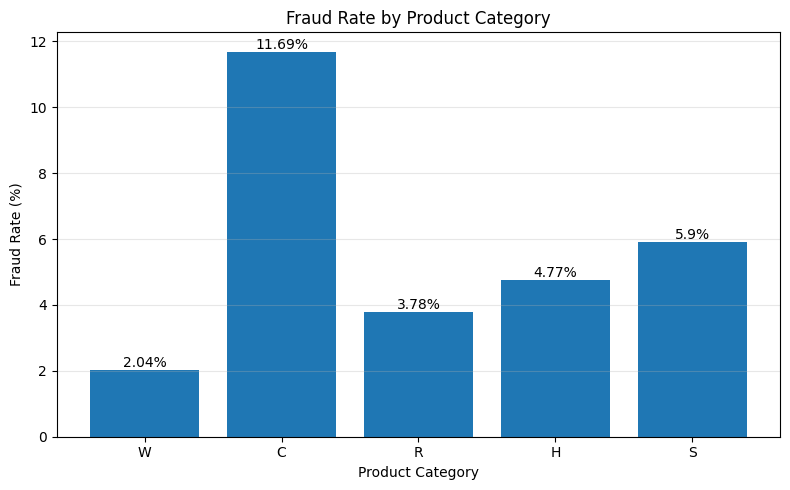

In [19]:
plt.figure(figsize=(8, 5))

plt.bar(
    product_stats["ProductCD"],
    product_stats["fraud_rate_percent"]
)

plt.title("Fraud Rate by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Fraud Rate (%)")

for i, value in enumerate(product_stats["fraud_rate_percent"]):
    plt.text(i, value, f"{value}%", ha="center", va="bottom")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# unify transaction dataset with identity dataset

data = transaction.merge(identity, on="TransactionID", how="left")

print("Merged dataset shape:", data.shape)
data.head()

Merged dataset shape: (590540, 434)


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [21]:
# check percentage of missing values per column

missing_ratio = data.isnull().mean().sort_values(ascending=False)
missing_ratio.head(20)

id_24    0.991962
id_25    0.991310
id_07    0.991271
id_08    0.991271
id_21    0.991264
id_26    0.991257
id_27    0.991247
id_23    0.991247
id_22    0.991247
dist2    0.936284
D7       0.934099
id_18    0.923607
D13      0.895093
D14      0.894695
D12      0.890410
id_04    0.887689
id_03    0.887689
D6       0.876068
id_33    0.875895
id_09    0.873123
dtype: float64

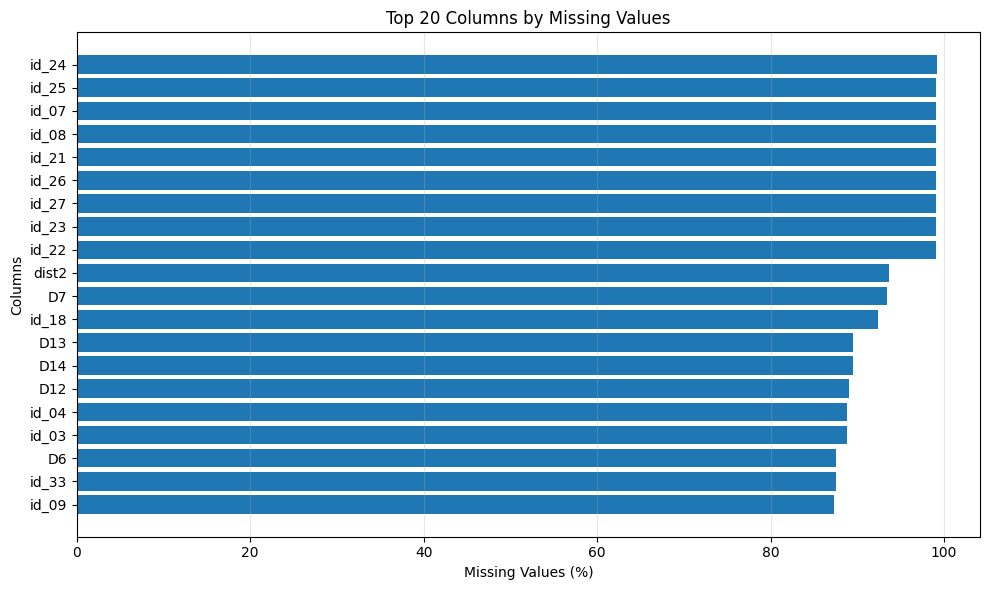

In [22]:
import matplotlib.pyplot as plt

missing_top20 = missing_ratio.head(20) * 100

plt.figure(figsize=(10, 6))
plt.barh(missing_top20.index[::-1], missing_top20.values[::-1])

plt.title("Top 20 Columns by Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Columns")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# eliminate columns with too many missing values (>90%)

cols_to_drop = missing_ratio[missing_ratio > 0.9].index
data = data.drop(columns=cols_to_drop)

print("Remaining columns:", data.shape[1])

Remaining columns: 422


In [24]:
# separate target variable from features

y = data["isFraud"]
X = data.drop(columns=["isFraud", "TransactionID"])

C:\Users\Uana\AppData\Local\Temp\ipykernel_15608\2529088917.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include="object").columns


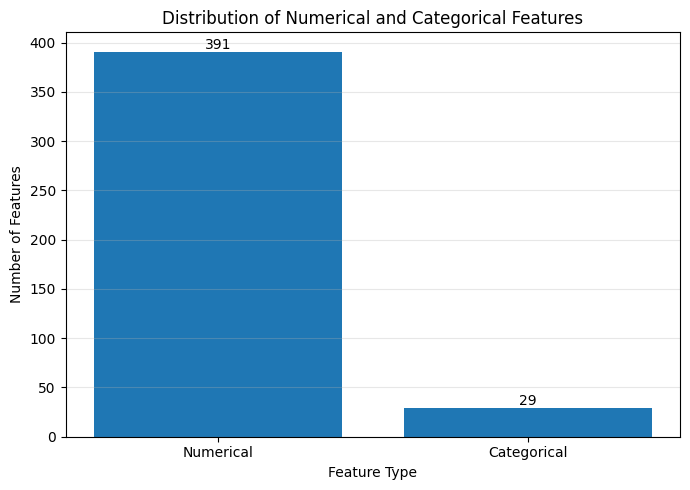

In [25]:
# feature type distribution after preprocessing

categorical_cols = X.select_dtypes(include="object").columns
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns

type_distribution = {
    "Numerical": len(numeric_cols),
    "Categorical": len(categorical_cols)
}

plt.figure(figsize=(7, 5))
plt.bar(type_distribution.keys(), type_distribution.values())

plt.title("Distribution of Numerical and Categorical Features")
plt.xlabel("Feature Type")
plt.ylabel("Number of Features")

for i, value in enumerate(type_distribution.values()):
    plt.text(i, value, str(value), ha="center", va="bottom")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# check categorical features

categorical_cols = X.select_dtypes(include="object").columns
print("Number of categorical features:", len(categorical_cols))
categorical_cols

Number of categorical features: 29


C:\Users\Uana\AppData\Local\Temp\ipykernel_15608\3585909151.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include="object").columns


Index(['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1',
       'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15',
       'id_16', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35',
       'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo'],
      dtype='str')

In [18]:
# check numeric features

numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns
print("Number of numeric features:", len(numeric_cols))

Number of numeric features: 391


##### Exploratory Data Analysis

In this stage, an exploratory data analysis was performed on the IEEE-CIS Fraud Detection dataset.

After merging the `transaction` and `identity` tables, the resulting dataset contains 590,540 transactions and more than 400 variables. This large dataset size allows the training of complex machine learning models.

The distribution of the target variable (`isFraud`) shows that approximately 3.5% of the transactions are fraudulent. This indicates a highly imbalanced dataset, meaning that metrics such as accuracy are not suitable for model evaluation. Instead, metrics such as ROC-AUC, Precision, Recall, and F1-score are more appropriate.

The analysis of missing values also shows that several variables contain more than 90% missing data. These columns were removed in order to reduce noise and simplify the dataset.

After removing these variables, the dataset still contains more than 400 features, including approximately 29 categorical variables and the remaining numeric variables. Therefore, categorical encoding techniques must be applied before training machine learning models.

##### Data Preprocessing

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

X_train = X_train.copy()
X_test = X_test.copy()

X_train[categorical_cols] = encoder.fit_transform(
    X_train[categorical_cols].astype(str)
)

X_test[categorical_cols] = encoder.transform(
    X_test[categorical_cols].astype(str)
)

feature_names = X_train.columns

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (472432, 420)
Test shape: (118108, 420)


##### Encoding of Categorical Features

The dataset was split into training and testing sets using an 80/20 ratio, with stratification applied to preserve the same proportion of fraudulent transactions in both subsets.

Categorical variables were converted into numerical values using Ordinal Encoding. The encoder was fitted exclusively on the training set and then applied to the testing set in order to prevent data leakage.

Any remaining missing values were handled using median imputation, where the median values were calculated from the training set. The same transformation was subsequently applied to the testing set.


In [28]:
from sklearn.impute import SimpleImputer
import pandas as pd

imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=feature_names,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=feature_names,
    index=X_test.index
)

##### Baseline Model: Logistic Regression

A Logistic Regression model was trained as a baseline classifier for fraud detection. 
This model provides a simple linear decision boundary and serves as a reference point before applying more complex algorithms such as Random Forest, LightGBM, or CatBoost.

The model outputs the probability of a transaction being fraudulent, which can later be used to compute evaluation metrics such as ROC-AUC, precision, recall, and F1-score.

##### Improved Logistic Regression Results

The improved Logistic Regression model achieved significantly better performance than the initial version. In particular, the recall for the fraud class increased substantially, which means that the model was able to identify a much larger proportion of fraudulent transactions.

The ROC-AUC score also improved, indicating a better overall discrimination between fraudulent and legitimate transactions.

However, the precision for the fraud class remained relatively low, which suggests that the model generated a considerable number of false positive alerts. This behavior is common in fraud detection, where increasing recall often comes at the cost of lower precision.

Overall, the improved Logistic Regression model provides a more reliable baseline, but more advanced algorithms are still required for better balance between fraud detection and false alarm reduction.

In [29]:
# improved logistic regression baseline

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

lr_pipeline.fit(X_train, y_train)

y_pred_lr = lr_pipeline.predict(X_test)
y_proba_lr = lr_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_lr))

              precision    recall  f1-score   support

           0       0.99      0.84      0.91    113975
           1       0.14      0.73      0.24      4133

    accuracy                           0.83    118108
   macro avg       0.56      0.78      0.57    118108
weighted avg       0.96      0.83      0.88    118108

ROC-AUC: 0.8631935947257524


### Random forest

In [30]:
# random forest model

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [31]:
# evaluation of random forest

from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, y_pred_rf))
print("ROC AUC:", roc_auc_score(y_test, y_prob_rf))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99    113975
           1       0.95      0.41      0.57      4133

    accuracy                           0.98    118108
   macro avg       0.96      0.71      0.78    118108
weighted avg       0.98      0.98      0.97    118108

ROC AUC: 0.9382867803039611


##### Random Forest Results

The Random Forest model achieved significantly better performance than Logistic Regression, obtaining a ROC-AUC score of 0.936.

For the fraudulent class, the model achieved very high precision, indicating that most transactions classified as fraudulent were indeed fraud cases. However, the recall score was lower, meaning that some fraudulent transactions remained undetected.

This result highlights an important trade-off in fraud detection systems: reducing false alerts may increase the likelihood of missing certain fraudulent transactions. For this reason, the final application incorporates a risk scoring mechanism in addition to binary classification, providing a more flexible and informative assessment of transaction risk.


#### LightGBM

In [32]:
# lightgbm model

import lightgbm as lgb

lgb_model = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

lgb_model.fit(X_train, y_train)

y_pred_lgb = lgb_model.predict(X_test)
y_proba_lgb = lgb_model.predict_proba(X_test)[:, 1]

In [35]:
print(classification_report(y_test, y_pred_lgb))
print("ROC AUC:", roc_auc_score(y_test, y_proba_lgb))

              precision    recall  f1-score   support

           0       0.99      0.89      0.94    113975
           1       0.21      0.82      0.34      4133

    accuracy                           0.89    118108
   macro avg       0.60      0.85      0.64    118108
weighted avg       0.97      0.89      0.92    118108

ROC AUC: 0.9303794819191049


##### LightGBM Results

The LightGBM model achieved strong performance in detecting fraudulent transactions. Compared to Random Forest, the model significantly increased the recall for the fraud class, identifying approximately 82% of fraudulent transactions.

This improvement indicates that LightGBM is more effective at capturing suspicious patterns in the dataset. However, the precision for the fraud class decreased, meaning that the model generated a larger number of false positive alerts.

This behavior is typical in fraud detection systems, where improving recall often leads to a reduction in precision. In practical scenarios, detecting a higher proportion of fraudulent transactions may be preferred, even if it results in additional manual reviews.

The ROC-AUC score remained high (approximately 0.93), confirming that the model maintains strong overall discrimination between legitimate and fraudulent transactions.

### CatBoost

In [36]:
# catboost model

from catboost import CatBoostClassifier

cat_model = CatBoostClassifier(
    iterations=200,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    verbose=0,
    random_state=42
)

cat_model.fit(X_train, y_train)

y_pred_cat = cat_model.predict(X_test)
y_prob_cat = cat_model.predict_proba(X_test)[:,1]

In [37]:
# evaluation of catboost

from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, y_pred_cat))
print("ROC AUC:", roc_auc_score(y_test, y_prob_cat))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99    113975
           1       0.90      0.33      0.48      4133

    accuracy                           0.98    118108
   macro avg       0.94      0.67      0.74    118108
weighted avg       0.97      0.98      0.97    118108

ROC AUC: 0.8871374749653002


##### CatBoost Results

The CatBoost model was evaluated as an additional gradient boosting algorithm designed for structured datasets. CatBoost is particularly effective in handling categorical variables and reducing overfitting through ordered boosting techniques.

In this experiment, the CatBoost model achieved a ROC-AUC score of approximately 0.89, indicating good overall discrimination between legitimate and fraudulent transactions.

The model produced high precision for the fraud class, meaning that most transactions predicted as fraudulent were indeed fraud cases. However, the recall for fraud remained relatively moderate, indicating that a significant portion of fraudulent transactions were not detected.

Compared to the other models, CatBoost behaved similarly to Random Forest by being more conservative in predicting fraud. As a result, it generated fewer false alarms but also missed more fraudulent transactions than models such as LightGBM.

### Model comparison table

In [39]:
# model comparison table

import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

results = []

models = {
    "Logistic Regression": (y_pred_lr, y_proba_lr),
    "Random Forest": (y_pred_rf, y_prob_rf),
    "LightGBM": (y_pred_lgb, y_proba_lgb),
    "CatBoost": (y_pred_cat, y_prob_cat)
}

for name, (pred, prob) in models.items():
    precision = precision_score(y_test, pred)
    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    roc = roc_auc_score(y_test, prob)

    results.append({
        "Model": name,
        "ROC-AUC": roc,
        "Precision (Fraud)": precision,
        "Recall (Fraud)": recall,
        "F1-score (Fraud)": f1
    })
results_df = pd.DataFrame(results)
results_df.sort_values("ROC-AUC", ascending=False)
results_df.round(3)


,Model,ROC-AUC,Precision (Fraud),Recall (Fraud),F1-score (Fraud)
0,Logistic Regression,0.863,0.140,0.731,0.235
1,Random Forest,0.938,0.945,0.413,0.575
2,LightGBM,0.930,0.213,0.816,0.338
3,CatBoost,0.887,0.903,0.331,0.485


##### Model Performance Comparison

The results of the evaluated machine learning models are summarized in the comparison table above. Each model was assessed using several metrics relevant to fraud detection, including ROC-AUC, precision, recall, and F1-score for the fraud class.

Logistic Regression achieved a moderate ROC-AUC score and a relatively high recall for fraudulent transactions. However, its precision was very low, meaning that the model generated a large number of false positive alerts.

Random Forest obtained the highest ROC-AUC score among the tested models and achieved very high precision for the fraud class. This indicates that when the model predicts fraud, it is usually correct. However, the recall was lower, meaning that a significant portion of fraudulent transactions remained undetected.

LightGBM demonstrated the highest recall for fraudulent transactions, successfully identifying a large proportion of fraud cases. Nevertheless, this improvement came at the cost of lower precision, resulting in more false positive alerts.

CatBoost showed a balanced behavior similar to Random Forest, with high precision but lower recall compared to LightGBM.

Overall, the comparison highlights the typical trade-off between precision and recall in fraud detection systems. Some models prioritize detecting more fraudulent transactions, while others focus on reducing the number of false alerts.

##### Final Model Selection

Based on the comparative evaluation, each model demonstrated different strengths in detecting fraudulent transactions.

Logistic Regression provided a useful baseline but generated a large number of false positives due to its low precision. Although the recall was relatively high, the overall performance was limited by the model’s linear nature.

Random Forest achieved the highest ROC-AUC score among all evaluated models and also obtained the highest F1-score for the fraud class. In addition, it showed very high precision, indicating that when the model predicts a transaction as fraudulent, the prediction is usually correct. Although the recall was lower than that of LightGBM, the model provided the best overall balance between fraud detection performance and false alert control.

LightGBM achieved the highest recall among all evaluated models, successfully identifying the majority of fraudulent transactions. However, this was accompanied by a much lower precision, which means that the model generated a large number of false positive alerts.

CatBoost produced good precision but lower recall and lower overall performance compared to Random Forest.

Considering the objective of building a reliable fraud detection system with strong discrimination ability and controlled false positive alerts, Random Forest was selected as the final model for the proposed system. Although LightGBM achieved higher recall, its lower precision would generate a larger number of false alerts, which may reduce the practical usability of the system.

In [40]:
# feature importance from random forest

import pandas as pd

feature_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values("importance", ascending=False)

feature_importance.head(20)

,feature,importance
1,TransactionAmt,0.031596
0,TransactionDT,0.029721
3,card1,0.025563
26,C13,0.024544
4,card2,0.022552
27,C14,0.022236
9,addr1,0.019125
120,V70,0.015673
12,P_emaildomain,0.012878
41,D15,0.012488


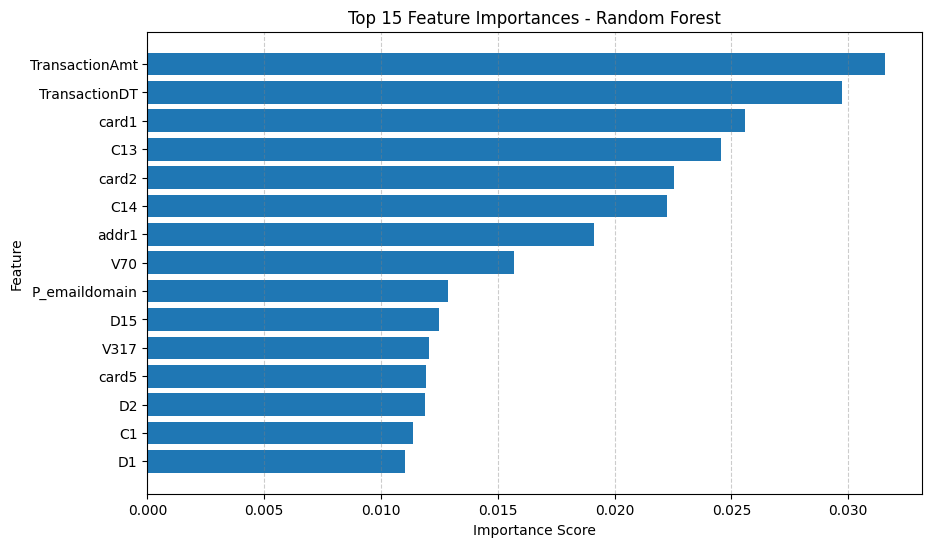

In [43]:
# plot top features

import matplotlib.pyplot as plt

top_features = feature_importance.head(15)

plt.figure(figsize=(10,6))
plt.barh(top_features["feature"], top_features["importance"])

plt.gca().invert_yaxis()
plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.grid(axis="x", linestyle="--", alpha=0.4, color="gray")

plt.show()

##### Feature Importance Analysis

To better understand how the Random Forest model makes predictions, feature importance was analyzed. Feature importance measures how much each variable contributes to the model's decision-making process.

The results show that `TransactionAmt` is the most influential feature, indicating that the transaction amount plays a major role in distinguishing fraudulent behavior from legitimate activity.

`TransactionDT` is also among the most important variables, suggesting that transaction timing contains relevant temporal patterns associated with fraud.

Several card-related attributes such as `card1`, `card2`, and `card5` also contribute significantly to the model’s predictions. These variables likely capture useful information related to card characteristics and recurring behavioral patterns.

Other important variables include behavioral and aggregated indicators such as `C13`, `C14`, `C1`, `D1`, `D2`, `D15`, and anonymized variables such as `V70` and `V317`. These features appear to encode hidden transactional relationships that are useful for fraud detection.

Overall, the feature importance analysis indicates that the Random Forest model relies on a combination of financial, temporal, behavioral, and card-related characteristics to distinguish fraudulent transactions from legitimate activity.

## Risk Scoring System


In [ ]:
# fraud probability from final model

fraud_prob = rf_model.predict_proba(X_test)[:,1]

In [ ]:
# convert probability to risk score

risk_score = fraud_prob * 100

In [69]:
# risk categories

import numpy as np

risk_category = np.where(
    risk_score < 30,
    "Legitimate",
    np.where(risk_score < 70, "Suspicious", "High Risk")
)

In [70]:
# final risk scoring table

results_table = pd.DataFrame({
    "Actual": y_test.values,
    "Fraud_Probability": np.round(fraud_prob, 3),
    "Risk_Score": np.round(risk_score, 1),
    "Risk_Category": risk_category
})

results_table.head(20)

,Actual,Fraud_Probability,Risk_Score,Risk_Category
0,0,0.00,0.0,Legitimate
1,0,0.00,0.0,Legitimate
2,0,0.01,1.0,Legitimate
3,0,0.00,0.0,Legitimate
4,0,0.00,0.0,Legitimate
5,0,0.01,1.0,Legitimate
6,0,0.03,3.0,Legitimate
7,0,0.01,1.0,Legitimate
8,0,0.00,0.0,Legitimate
9,0,0.01,1.0,Legitimate


In [71]:
# distribution of risk categories

results_table[results_table["Risk_Category"] != "Legitimate"].head(20)
results_table["Risk_Category"].value_counts()

Risk_Category
Legitimate    115397
Suspicious      1474
High Risk       1237
Name: count, dtype: int64

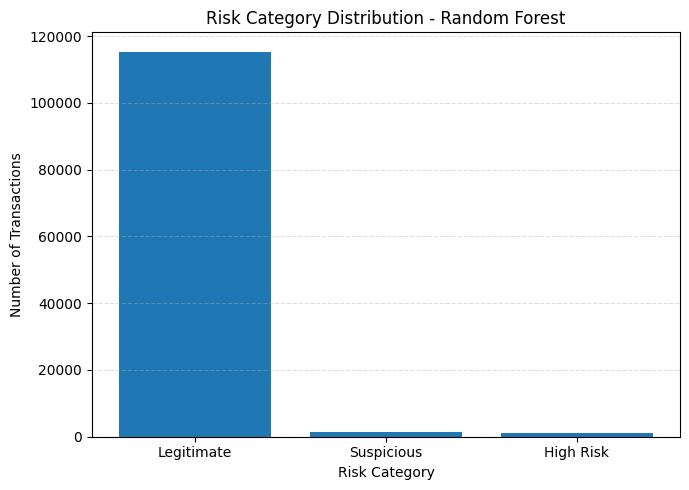

In [79]:
# risk category distribution

risk_counts = results_table["Risk_Category"].value_counts()

plt.figure(figsize=(7,5))

plt.bar(
    risk_counts.index,
    risk_counts.values
)

plt.xlabel("Risk Category")
plt.ylabel("Number of Transactions")
plt.title("Risk Category Distribution - Random Forest")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

#### Risk Category Distribution

The distribution of risk categories shows that the majority of transactions were classified as legitimate, which is expected in highly imbalanced fraud detection datasets.

A smaller number of transactions were categorized as Suspicious or High Risk, indicating transactions with elevated fraud probability scores generated by the Random Forest model.

This type of risk-based categorization can support real-world fraud monitoring systems by helping analysts prioritize transactions that require additional verification or manual review.

##### Fraud Risk Scoring System

After selecting the Random Forest model as the final classifier, a fraud risk scoring mechanism was implemented in order to simulate a real-world fraud monitoring system.

The model outputs the probability that a transaction is fraudulent. This probability was transformed into a risk score ranging from 0 to 100, making the results easier to interpret and integrate into monitoring and decision-making processes.

Based on the calculated risk score, transactions were grouped into three categories:

- Legitimate (Low Risk) – transactions with a risk score below 30
- Suspicious (Medium Risk) – transactions with a risk score between 30 and 70
- High Risk – transactions with a risk score above 70

Transactions classified as High Risk are not automatically considered fraudulent. Instead, they represent transactions with a significantly elevated fraud probability that may require additional verification, monitoring, or manual review.

This classification approach reflects how modern fraud detection systems operate in practice, where risk scoring mechanisms are used to prioritize suspicious activities and reduce unnecessary false alerts.

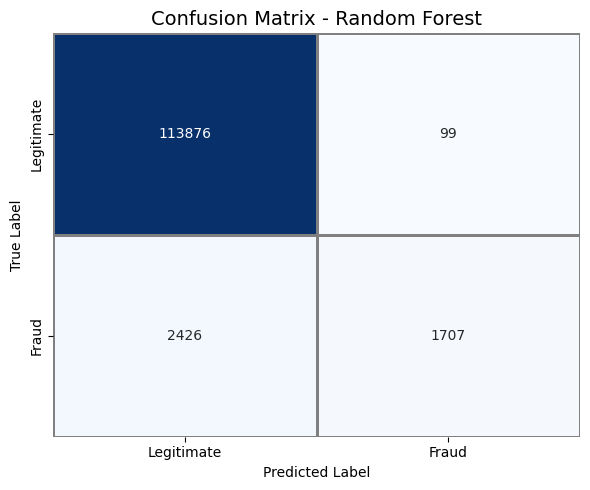

In [73]:
# confusion matrix visualization

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    linewidths=1,
    linecolor="gray"
)

plt.title("Confusion Matrix - Random Forest", fontsize=14)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks([0.5,1.5], ["Legitimate","Fraud"])
plt.yticks([0.5,1.5], ["Legitimate","Fraud"])

plt.grid(False)
plt.tight_layout()

plt.show()

##### Confusion Matrix Analysis

The confusion matrix provides a detailed overview of how the Random Forest model classified transactions.

The results show that the model correctly classified **113,876 legitimate transactions** as non-fraud and only **99 legitimate transactions** were incorrectly flagged as fraudulent. This demonstrates that the model has a very low false positive rate.

For fraudulent transactions, the model successfully detected **1,707 fraud cases**, while **2,426 fraudulent transactions were missed** and classified as legitimate.

These results highlight the typical trade-off in fraud detection systems between minimizing false alerts and maximizing fraud detection capability. Although some fraudulent transactions remain undetected, the model demonstrates strong overall discrimination ability and a very low false positive rate, making it suitable for practical fraud monitoring scenarios.

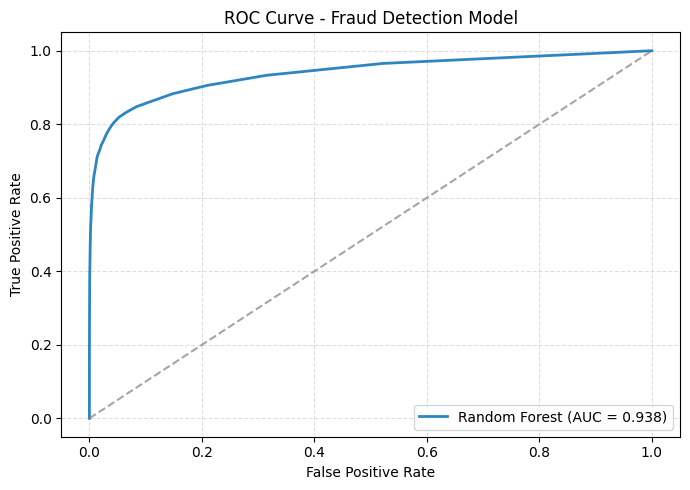

In [ ]:
# ROC curve visualization

from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    color="#2E86C1",
    lw=2,
    label=f"Random Forest (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    color="gray",
    alpha=0.7
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")

plt.grid(True, linestyle="--", alpha=0.4)

plt.legend(loc="lower right")

plt.tight_layout()

plt.show()

##### ROC Curve Analysis

The Receiver Operating Characteristic (ROC) curve illustrates the trade-off between the true positive rate and the false positive rate across different classification thresholds.

The Random Forest model achieved an Area Under the Curve (ROC-AUC) score of approximately 0.938, indicating a strong ability to distinguish between fraudulent and legitimate transactions.

A ROC-AUC value close to 1 indicates excellent classification capability, while a value near 0.5 would represent random classification performance. The high ROC-AUC score obtained in this experiment confirms that the selected model provides strong discrimination ability.

The ROC curve demonstrates that the Random Forest model maintains an effective balance between fraud detection capability and false positive control across multiple classification thresholds, which is highly desirable in practical fraud detection systems.

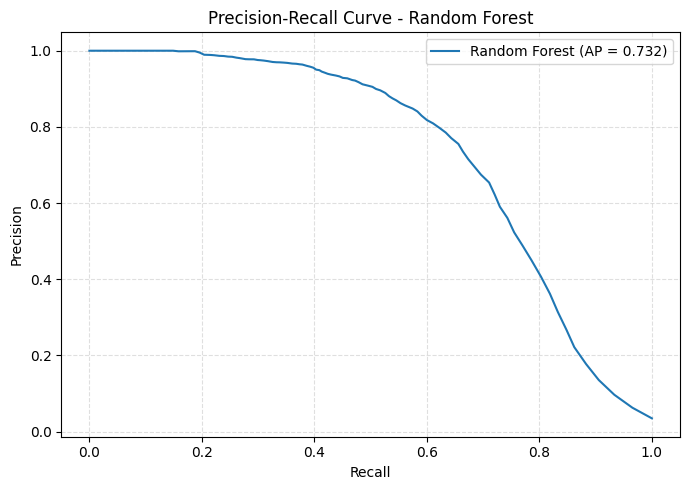

In [77]:
# Precision-Recall Curve

from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

precision, recall, thresholds = precision_recall_curve(y_test, y_prob_rf)
avg_precision = average_precision_score(y_test, y_prob_rf)

plt.figure(figsize=(7,5))
plt.plot(recall, precision, label=f"Random Forest (AP = {avg_precision:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Random Forest")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()

plt.tight_layout()
plt.show()

#### Precision-Recall Curve Analysis

The Precision-Recall curve provides additional insight into model performance on highly imbalanced datasets, where ROC-AUC alone may not fully reflect fraud detection effectiveness.

The Random Forest model achieved an Average Precision (AP) score of approximately 0.73, indicating strong capability in identifying fraudulent transactions while maintaining relatively high precision across different recall levels.

The curve highlights the trade-off between precision and recall. As recall increases and the model attempts to detect a larger proportion of fraud cases, precision gradually decreases due to the increase in false positive alerts.

This analysis confirms that the selected model maintains a good balance between fraud detection effectiveness and alert reliability, which is essential in practical financial fraud monitoring systems.

### Threshold Tuning

In [75]:
# threshold tuning

import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.1, 0.9, 0.05)

threshold_results = []

for t in thresholds:
    
    preds = (y_prob_rf >= t).astype(int)
    
    precision = precision_score(y_test, preds)
    recall = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    
    threshold_results.append({
        "Threshold": t,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Precision,Recall,F1
0,0.10,0.449626,0.786112,0.572057
1,0.15,0.653975,0.710622,0.681122
2,0.20,0.755364,0.655940,0.702150
3,0.25,0.817942,0.600048,0.692254
4,0.30,0.862316,0.553109,0.673939
5,0.35,0.896017,0.517058,0.655723
6,0.40,0.917440,0.478587,0.629035
7,0.45,0.932522,0.444713,0.602228
8,0.50,0.945183,0.413017,0.574844
9,0.55,0.960313,0.386402,0.551070


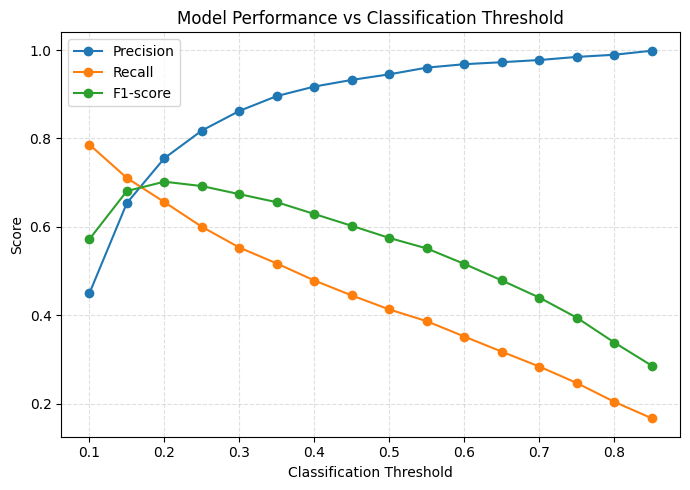

In [ ]:
# precision recall vs threshold

plt.figure(figsize=(7,5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1-score"
)

plt.grid(True, linestyle="--", alpha=0.4)

plt.xlabel("Classification Threshold")
plt.ylabel("Metric Value")
plt.title("Threshold Optimization - Random Forest")

plt.legend()

plt.tight_layout()

plt.show()

##### Classification Threshold Optimization

In binary classification models, the default classification threshold is typically set to 0.5. However, in fraud detection systems, adjusting this threshold can significantly influence the balance between detecting fraudulent transactions and minimizing false alerts.

To analyze this behavior, the model performance was evaluated across multiple classification thresholds ranging from 0.10 to 0.85. For each threshold value, precision, recall, and F1-score were computed.

The results show a clear trade-off between precision and recall. When the threshold is low (e.g., 0.10), the model detects a large proportion of fraudulent transactions (high recall ≈ 0.78) but generates more false positives, resulting in lower precision.

As the threshold increases, precision steadily improves, reaching values close to 1.0 at higher thresholds. However, this comes at the cost of lower recall, meaning that more fraudulent transactions are missed.

The F1-score reaches its highest value around thresholds between **0.20 and 0.25**, indicating a better balance between precision and recall in this region.

These results demonstrate that threshold selection is a critical component of fraud detection systems. Depending on operational requirements, organizations may prioritize higher recall to maximize fraud detection or higher precision to minimize false positive alerts. Therefore, the classification threshold should be adapted according to the specific risk management strategy of the institution.

In [80]:
# Final Model Save
import joblib

joblib.dump(rf_model, "../models/random_forest_model.pkl")
joblib.dump(imputer, "../models/imputer.pkl")
joblib.dump(encoder, "../models/encoder.pkl")
joblib.dump(feature_names.tolist(), "../models/feature_names.pkl")

['../models/feature_names.pkl']

In [81]:
# For simulation
joblib.dump(categorical_cols, "../models/categorical_cols.pkl")

['../models/categorical_cols.pkl']